## **Σ estimation error and regularization**

To construct the unbiased sample covariance for an investment portfolio, we use the formula

$$S_{ij}=\frac{1}{T-1}\sum_{t=1}^{T}(r_{i,t}-\bar r_i)(r_{j,t}-\bar r_j)$$

which can be written in matrix notation as

$$S_{ij}=\frac{1}{T-1} X^T X$$

In [1]:
import sys
from pathlib import Path

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "portfolio_math.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find the project root containing src/portfolio_math.py.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytest

from src.portfolio_math import global_minimum_variance, portfolio_variance

In [3]:
# Define a sample return matrix
return_matrix = np.array([
    [3, 7],
    [2, 4],
    [1, 4]
])

In [4]:
def sample_covariance(returns):
    #1. Number of assets
    T_obs = returns.shape[0]

    #2. Mean
    mu = returns.mean(axis=0, keepdims = True)

    # 3.Demeaned returns
    demeaned_returns = returns - mu

    #4. Sample covariance
    return (demeaned_returns.T @ demeaned_returns) / (T_obs - 1)

sample_covariance(return_matrix)

array([[1. , 1.5],
       [1.5, 3. ]])

**Construct a true $\Sigma$ with $N = 35$ (the size of the IPC) based on a one-factor model: $\Sigma = \sigma_m^2\beta\beta^\top + D$, using:**
- $\beta_i \sim U(0.5, 1.5)$
- $\sigma_m = 0.01$ (daily)
- idiosyncratic volatilities $\sim U(0.01, 0.02)$ on the diagonal of $D$
- seed 42.

In [5]:
seed = 42
rng = np.random.default_rng(seed)

N = 35

beta = rng.uniform(0.5,1.5, size=N)
sigma_m = 0.01
idio_vol = rng.uniform(0.01, 0.02, size=N)

Sigma = sigma_m**2 * np.outer(beta, beta) + np.diag(idio_vol**2)

(35, 35) True


<Axes: >

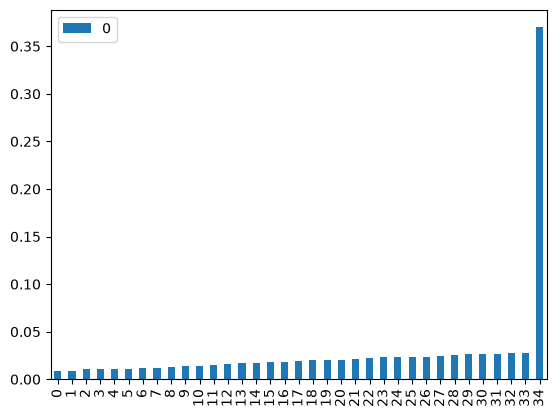

In [6]:
# Pruebas
print(Sigma.shape, np.allclose(Sigma, Sigma.T))

Sigma_eigs = np.linalg.eigvalsh(Sigma)
Sigma_eigs
participation = []
total_eigs = Sigma_eigs.sum()

for eig in Sigma_eigs:
    participation.append(eig / total_eigs)

participation = pd.DataFrame(participation)
participation.plot(kind="bar")


**For T $\in$ {30, 40, 60, 120, 250, 500, 1000, 5000}, perform 200 replicates:**
- Simulate normal returns
- Estimate S and record the ordered eigenvalues
- λ_min
- λ_max
- Condition number
- Relative Frobenius error $\|S-\Sigma\|_F/\|\Sigma\|_F$.

In [7]:
# Lets begin with an example matrix
sigma_example = np.array([
    [4, 2],
    [2, 5]
])

In [8]:
# Define the shape of our returns matrix: T days, N assets
N = sigma_example.shape[0]
T = 100000

# 1. Apply Cholesky decomposition to the covariance matrix Sigma
L = np.linalg.cholesky(sigma_example)

Z = rng.standard_normal((T, N))

R = Z @ L.T

S = sample_covariance(R)

In [9]:
eigs = np.linalg.eigvalsh(S)

In [10]:
eigs = np.linalg.eigvalsh(S)
# Min and Max  eigenvalues
eig_min = eigs[0]
eig_max = eigs[-1]

# Condition number
condition_number = eig_max / eig_min

# Relative Frobenius error
rel_frobenius_error = np.linalg.norm(S - sigma_example, 'fro') / np.linalg.norm(sigma_example, 'fro')

### **Once we understand the process, we can build functions of it and begin the exercise**

In [11]:
def simulate_returns(Sigma, T, rng, mu=None):
    L = np.linalg.cholesky(Sigma) # 1. Apply Cholesky decomposition to the covariance matrix Sigma
    N = Sigma.shape[0]
    Z = rng.standard_normal((T, N)) # 2. Generate random noise. Mean 0, standard deviation 1
    R = Z @ L.T # 3. Compute the returns

    if mu is not None:
        R = R + mu

    return R

In [12]:
def spectrum_stats(S):
    """
    Inputs a covariance matrix
    Returns the spectrum stats in the following order:
    Ordered eigenvalues, Min eigenvalue, Max eigenvalue, Condition number
    """
    eigs = np.linalg.eigvalsh(S)
    eig_min, eig_max = eigs[0], eigs[-1]
    tol = eig_max * S.shape[0] * np.finfo(float).eps
    condition_number = np.inf if eig_min <= tol else eig_max / eig_min
    
    return eigs, eig_min, eig_max, condition_number


In [13]:
def relative_frobenius_error(Sigma, S):
    """
    Inputs a true covariance matrix and an estimation
    Outputs the Relative Frobenius Error
    """
    return np.linalg.norm(S - Sigma, 'fro') / np.linalg.norm(Sigma, 'fro')

In [14]:
# 1. Define the basic info for the simulation
T_values= np.array([30, 40, 60, 120, 250, 500, 1000, 5000])
n_replicates = 200
N = Sigma.shape[0]
eigs_dict = {}
metrics = []

In [15]:
# 2. Begin the simulation
for t in T_values:
    # 1. Create a n_replicates x N empty array
    eigs_dict[t] = np.empty((n_replicates, N)) 
    for rep in range(n_replicates):
        
        #2. Calculate the relevant metrics
        R = simulate_returns(Sigma = Sigma, T = t, rng = rng)
        S = sample_covariance(R)
        eigs, eig_min, eig_max, condition_number = spectrum_stats(S)
        rel_frobenius_error = relative_frobenius_error(Sigma=Sigma, S=S)
        
        #3. Store the metrics in our dictionary or list. 1 dict/ list per t
        eigs_dict[t][rep, :] = eigs
        metrics_dict = {
            "T": t,
            "Replica": rep,
            "lambda_min": eig_min,
            "lambda_max": eig_max,
            "cond": condition_number,
            "frob_rel": rel_frobenius_error
        }
        metrics.append(metrics_dict)

In [16]:
scalar_metrics = pd.DataFrame(metrics)

In [17]:
scalar_metrics.shape

(1600, 6)

In [18]:
scalar_metrics.tail(20)

,T,Replica,lambda_min,lambda_max,cond,frob_rel
1580,5000,180,0.000100,0.004613,45.957234,0.049251
1581,5000,181,0.000100,0.004377,43.897545,0.036176
1582,5000,182,0.000100,0.004377,43.739641,0.035739
1583,5000,183,0.000101,0.004535,45.034974,0.036830
1584,5000,184,0.000101,0.004483,44.451546,0.033481
1585,5000,185,0.000101,0.004409,43.517005,0.038905
1586,5000,186,0.000100,0.004555,45.585674,0.041697
1587,5000,187,0.000100,0.004442,44.297438,0.035899
1588,5000,188,0.000100,0.004522,45.121574,0.039998
1589,5000,189,0.000102,0.004445,43.720482,0.034985


### **Figure 1**
The spectrum of $S$ versus that of $\Sigma$ for $T = 60$ and $T = 1000$, on a logarithmic scale.

For the first figure, I need:
1. The 35 eigenvalues ​​of the original $\Sigma$
2. The average of the 35 eigenvalues ​​from the 200 replicates generated for T = 60
3. The average of the 35 eigenvalues ​​from the 200 replicates generated for T = 1000

In [19]:
# 1. Already exists as Sigma_eigs

# 2. Average of the 35 eigenvalues ​​from the 200 replicates performed for T = 60
eigs_mean_T60 = eigs_dict[60].mean(axis=0)

# 3. Average of the 35 eigenvalues ​​from the 200 replicates performed for T = 1,000
eigs_mean_T1000 =eigs_dict[1000].mean(axis=0)

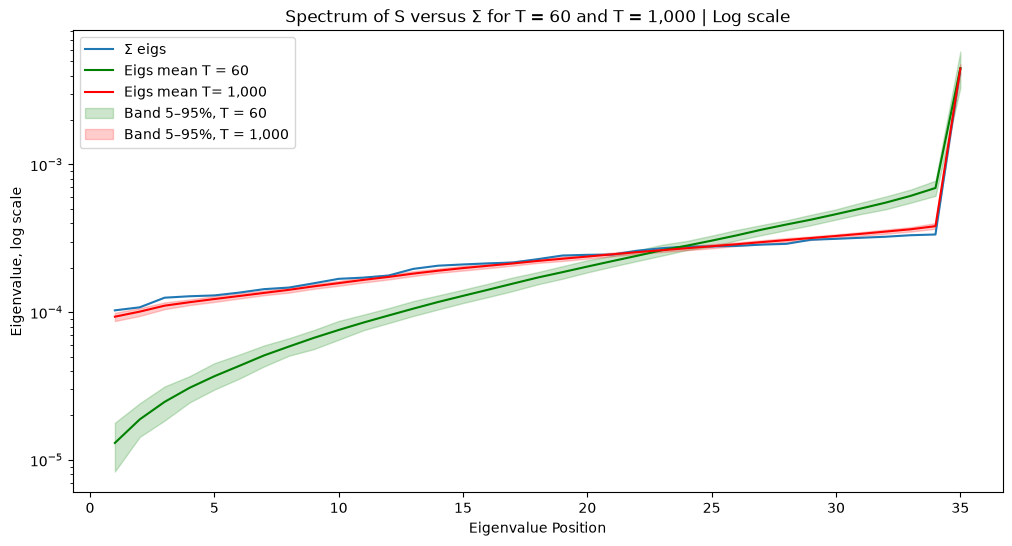

In [20]:
fig, ax = plt.subplots(figsize=(12,6))
x = list(range(1, N+1)) # X axis spanning our 35 eigenvalues
y1, y2, y3 = Sigma_eigs, eigs_mean_T60, eigs_mean_T1000 

# Compute the 90th percentile for T = 60 and  T = 1,000
T60_90_percentile = np.percentile(eigs_dict[60], [5, 95], axis=0) 
T1000_90_percentile = np.percentile(eigs_dict[1000], [5, 95], axis=0)
Sigma_90_percentile = np.percentile(Sigma_eigs, [5, 95], axis=0)

# Use semilogy to visualize the eigenvalues in log scale
ax.semilogy(x, y1, label='Σ eigs')
ax.semilogy(x, y2, color = 'green', label='Eigs mean T = 60')
ax.semilogy(x, y3, color = 'red', label='Eigs mean T= 1,000')

# Add a shaded band using the 5th and 95th percentiles of each column
T60_p5, T60_p95 = np.percentile(eigs_dict[60], [5, 95], axis=0)
ax.fill_between(x, T60_p5, T60_p95, color='green', alpha=0.2, label='Band 5–95%, T = 60')

# Add a title and labels to x and y axis
plt.title("Spectrum of S versus Σ for T = 60 and T = 1,000 | Log scale")
plt.xlabel("Eigenvalue Position")
plt.ylabel("Eigenvalue, log scale")

T1000_p5, T1000_p95 = np.percentile(eigs_dict[1000], [5, 95], axis=0)
ax.fill_between(x, T1000_p5, T1000_p95, color='red', alpha=0.2, label='Band 5–95%, T = 1,000')
plt.legend()
plt.show()

### **Figure 2**
For the second figure I need
1. $\kappa(\Sigma)$
2. Average condition number of S
3. $T/N$

In [21]:
# 1. k(Σ) 
kappa_true = Sigma_eigs[-1] / Sigma_eigs[0]

# 2. Average condition number of S per T
valid = scalar_metrics[np.isfinite(scalar_metrics["cond"])]
avg_cond_number_S_T = valid.groupby("T")["cond"].mean()

# 3. Median condition number of S per T
median_cond_number_t = valid.groupby("T")["cond"].median()

# 4. T/N
T_over_N = avg_cond_number_S_T.index / N

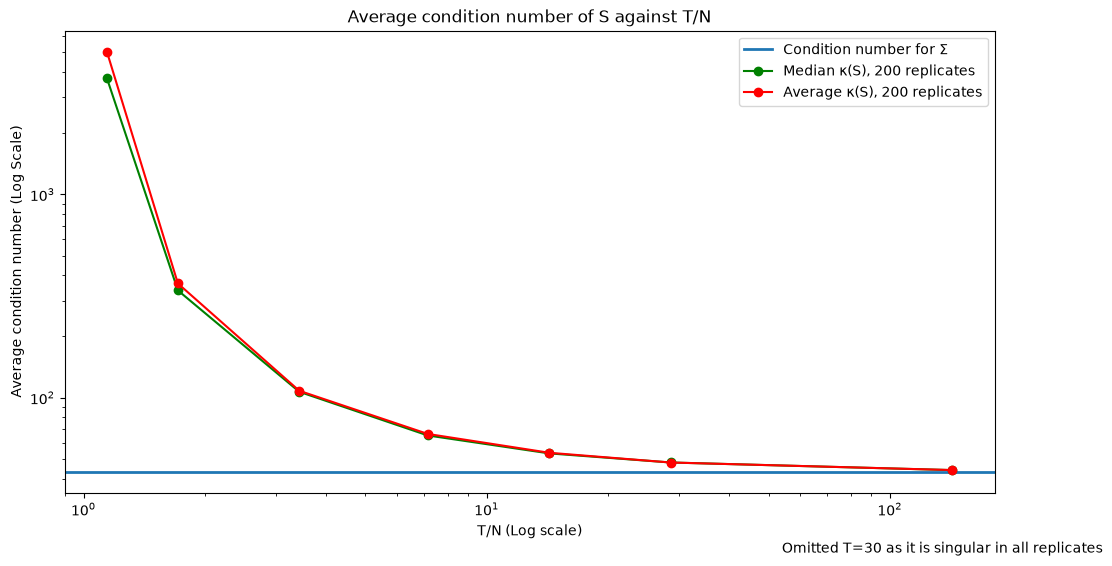

In [22]:
fig, ax = plt.subplots(figsize=(12,6))

# Define our x and y variables
x = T_over_N
y = avg_cond_number_S_T

ax.axhline(kappa_true, linewidth=2, label="Condition number for Σ")
ax.loglog(T_over_N, median_cond_number_t, color="green", marker="o" ,label = "Median κ(S), 200 replicates" )
ax.loglog(x, y, color="red", marker="o" ,label = "Average κ(S), 200 replicates")

plt.title("Average condition number of S against T/N")
plt.xlabel("T/N (Log scale)")
plt.ylabel("Average condition number (Log Scale)")
plt.figtext(0.99, 0.01, "Omitted T=30 as it is singular in all replicates", horizontalalignment='right')

plt.legend()
plt.show()

## **Parte C: Tests**

Tests (20 min, los escribes tú). Escribe tests/test_covariance.py con al menos tres tests: 
- Sample_covariance coincida con np.cov 
- El resultado sea simétrico y PSD (con eigvalsh y una tolerancia)
- El rango sea ≤ T−1 cuando T < N.

In [23]:
rng = np.random.default_rng(42)
R = rng.standard_normal((100, 5))
S = sample_covariance(R)
eigs = np.linalg.eigvalsh(S)
eig_min, eig_max = eigs[0], eigs[-1]
tol = eig_max * S.shape[0] * np.finfo(float).eps
assert np.allclose(S, S.T) and (eig_min >= tol)

In [24]:
T, N = 10, 20
rng = np.random.default_rng(42)
R = rng.standard_normal((T,N))
S = sample_covariance(S)
rank_S = np.linalg.matrix_rank(S)
assert rank_S <= (T - 1)

## **Estimated GMV underestimates its own risk: 2-asset example**

$$\Sigma = \begin{pmatrix}4 & 1\\ 1 & 9\end{pmatrix},\qquad S_a = \begin{pmatrix}3 & 1\\ 1 & 10\end{pmatrix},\qquad S_b = \begin{pmatrix}5 & 1\\ 1 & 8\end{pmatrix}$$

Assume that the estimator results in either $S_a$ or $S_b$, each with a probability of $1/2$.

1. Verify that the estimator is unbiased: $\frac{1}{2}(S_a + S_b) = \Sigma$.
2. Using the formula for the 2-asset global minimum variance (GMV) portfolio, $w_1 = \dfrac{\sigma_2^2 - \sigma_{12}}{\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}}$, calculate $w^*$, $\hat{w}_a$, and $\hat{w}_b$. The results will be fractions with a denominator of 11, so work with fractions rather than decimals.
3. Calculate three quantities: the reported variance for each $\hat{w}$ (using its corresponding $S$ matrix), the true variance for each $\hat{w}$ (using $\Sigma$), and the true minimum variance, $w^{*\top}\Sigma w^*$.
4. Compute the averages and verify that the chain of inequalities holds.

$$E[\hat w^\top S \hat w] \;\le\; w^{*\top}\Sigma w^* \;\le\; E[\hat w^\top \Sigma \hat w]$$

In [25]:
# Define the matrices
sigma_example = np.array([
    [4,1],
    [1, 9] 
])

Sa_example = np.array([
    [3, 1],
    [1, 10]
])

Sb_example = np.array([
    [5, 1],
    [1, 8]
])

In [26]:
# 1. Verify that the estimation is unbiased
print(sigma_example == (Sa_example + Sb_example) / 2)

# 2. Compute w*, ŵ_a and ŵ_b
w_star_example = global_minimum_variance(sigma_example)
wa_sa_example = global_minimum_variance(Sa_example)
wb_sb_example = global_minimum_variance(Sb_example)

# 3. Compute the variance for ŵ_a and S_b, ŵ_b and S_b, ŵ_a and Σ, ŵ_b and Σ and the true minimum variance
var_sigma_example = portfolio_variance(w_star_example, sigma_example)

var_wa_Sa_example = portfolio_variance(wa_sa_example, Sa_example)
var_wb_Sb_example = portfolio_variance(wb_sb_example, Sb_example)

var_wa_Sigma_example = portfolio_variance(wa_sa_example, sigma_example)
var_wb_Sigma_example = portfolio_variance(wb_sb_example, sigma_example)

# 4. Average out a and b and verify the chain of inequalities.
avg_w_S = (var_wa_Sa_example + var_wb_Sb_example) / 2
avg_w_Sigma = (var_wa_Sigma_example + var_wb_Sigma_example) / 2

assert avg_w_S <= var_sigma_example <= avg_w_Sigma

[[ True  True]
 [ True  True]]


## **Now, using our $\Sigma$ matrix for 35 assets with the $T$ values we used before (excluding $T=30$).**

For each of the 200 replications, we will calculate $\hat{w} = \text{GMV}(S)$ and record three values: 
1. The reported variance $\hat{w}^\top S \hat{w}$
2. The true variance $\hat{w}^\top \Sigma \hat{w}$
3. The constant $w^{*\top} \Sigma w^*$.

**Figure 3: The three average quantities plotted against $T/N$ on a logarithmic scale, with $w^{*\top} \Sigma w^*$ shown as a horizontal line.**

In [27]:
# 1. Define the basic info for the simulation
T_values = np.array([40, 60, 120, 250, 500, 1000, 5000])
n_replicates = 200
N = Sigma.shape[0]
metrics = []

#2. Calculate w* and the True minimum variance since they're constants 
w_star = global_minimum_variance(Sigma)
var_sigma = portfolio_variance(w_star, Sigma)

In [28]:
for t in T_values:
    # 1. Create a n_replicates x N empty array 
    for rep in range(n_replicates):
        
        #2. Simulate  the returns and S
        R = simulate_returns(Sigma = Sigma, T = t, rng = rng)
        S = sample_covariance(R)

        #3. Compute w* and ŵ
        w_hat = global_minimum_variance(S)

        # 4. Compute the variance for (ŵ,S), the variance for (ŵ,Σ) and the ratio for true vs reported variance
        var_w_hat_S = portfolio_variance(w_hat, S)
        var_w_hat_Sigma = portfolio_variance(w_hat, Sigma)
        true_var_vs_rep_var = var_w_hat_Sigma / var_w_hat_S

        # 5. Store the variables for T, Replica, and the metrics calculated in 4.
        gmv_dict = {
            "T": t,
            "Replica": rep,
            "ŵᵀ S ŵ": var_w_hat_S,
            "ŵᵀ Σ ŵ": var_w_hat_Sigma,
            "True var / Rep var": true_var_vs_rep_var 
        }

        metrics.append(gmv_dict)

gmv_metrics = pd.DataFrame(metrics)

In [29]:
# Compute the average variance per T for (ŵ,Σ), (ŵ,S) and the mean and median True var / Rep var ratio.
avg_var_w_hat_S_per_T = gmv_metrics.groupby("T")["ŵᵀ S ŵ"].mean()
avg_var_w_hat_Sigma_per_T = gmv_metrics.groupby("T")["ŵᵀ Σ ŵ"].mean()
mean_ratio_var_over_T = gmv_metrics.groupby("T")["True var / Rep var"].mean()
median_ratio_var_over_t = gmv_metrics.groupby("T")["True var / Rep var"].median()

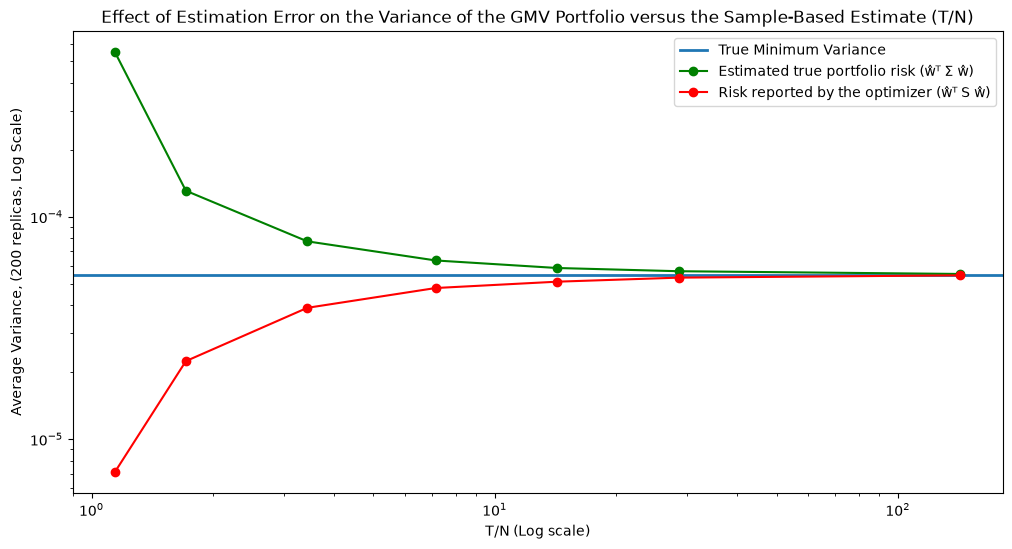

In [30]:
fig, ax = plt.subplots(figsize=(12,6))

# Define X 
x = T_over_N

ax.axhline(var_sigma, linewidth=2, label = "True Minimum Variance")
ax.loglog(x, avg_var_w_hat_Sigma_per_T, color="green", marker="o", label="Estimated true portfolio risk (ŵᵀ Σ ŵ)")
ax.loglog(x, avg_var_w_hat_S_per_T, color="red", marker="o", label="Risk reported by the optimizer (ŵᵀ S ŵ)")

ax.set_title("Effect of Estimation Error on the Variance of the GMV Portfolio versus the Sample-Based Estimate (T/N)")
ax.set_xlabel("T/N (Log scale)")
ax.set_ylabel("Average Variance, (200 replicas, Log Scale)")

ax.legend()
plt.show()

**Figure 4: The ratio of true risk to reported risk plotted against $T/N$.** 
This is the figure to be included in the paper, as it quantifies the extent to which the GMV estimate is misleading given the sample size (using the IPC dataset).

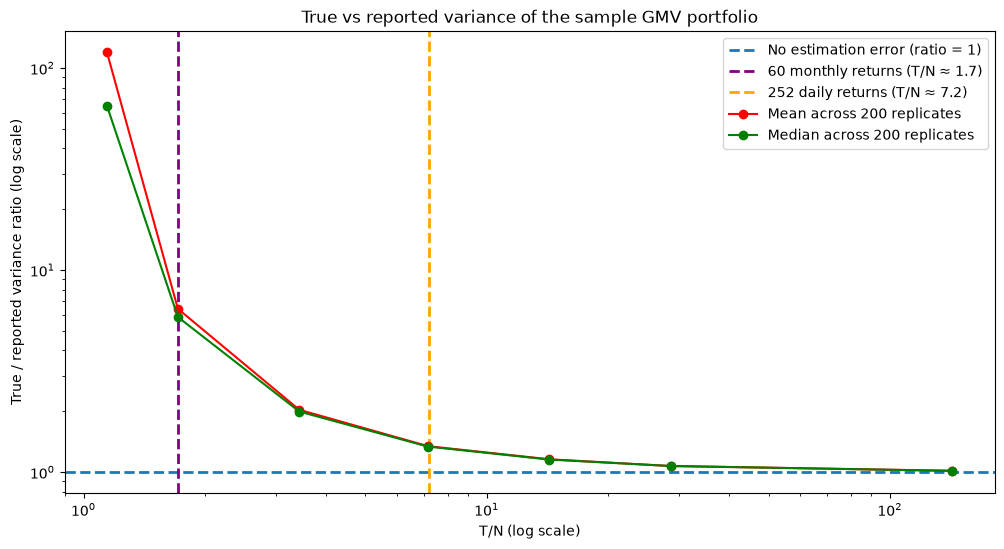

In [31]:
fig, ax = plt.subplots(figsize=(12,6))

# Define X 
x = T_over_N

ax.axhline(1, linestyle="--", linewidth=2, label = "No estimation error (ratio = 1)")
ax.axvline(60/35, color="purple", linestyle="--", linewidth=2, label = "60 monthly returns (T/N ≈ 1.7)")
ax.axvline(252/35, color = "orange", linestyle="--", linewidth=2, label = "252 daily returns (T/N ≈ 7.2)")
ax.loglog(x, mean_ratio_var_over_T, color="red", marker="o", label="Mean across 200 replicates")
ax.loglog(x, median_ratio_var_over_t, color="green", marker="o", label="Median across 200 replicates")

ax.set_title("True vs reported variance of the sample GMV portfolio")
ax.set_xlabel("T/N (log scale)")
ax.set_ylabel("True / reported variance ratio (log scale)")

ax.legend()
plt.show()

## **Tests**

We have observed that the chain of inequalities $E[\hat w^\top S\hat w] \le w^{*\top}\Sigma w^* \le E[\hat w^\top\Sigma\hat w]$ holds on average. The following tests will explore the reasons why. 

These tests examine the two inequalities as they apply to individual samples, without averaging.

- **Test 1 - $\hat w^\top S\hat w \le w^{*\top}S w^*$**: When estimating the Global Minimum Variance (GMV) portfolio using $S$, $\hat w$ is the optimal portfolio; therefore, $w^*$ cannot have a lower variance according to $S$.

- **Test 2 - $w^{*\top}\Sigma w^* \le \hat w^\top\Sigma\hat w$**: When estimating the GMV portfolio using the true covariance matrix $\Sigma$, $w^*$ is the optimal portfolio. Consequently, the portfolio selected by the optimizer, $\hat w$, has a true variance that is greater than or equal to the minimum achievable variance.

In [32]:
def one_factor_covariance(N, seed, sigma_m=0.01,
                          beta_range=(0.5, 1.5), idio_range=(0.01, 0.02)):
    rng = np.random.default_rng(seed)

    beta = rng.uniform(*beta_range, size=N)
    idio_vol = rng.uniform(*idio_range, size=N)

    Sigma = sigma_m**2 * np.outer(beta, beta) + np.diag(idio_vol**2)
    
    return Sigma

In [33]:
def _gmv_setup(seed, T, N=35):
    Sigma = one_factor_covariance(N, seed=42)
    rng = np.random.default_rng(seed)
    R = simulate_returns(Sigma, T, rng)
    S = sample_covariance(R)
    return Sigma, S, global_minimum_variance(Sigma), global_minimum_variance(S)

In [34]:
# Test 1
@pytest.mark.parametrize("seed", range(20))
@pytest.mark.parametrize("T", [40, 100, 1000])
def test_reported_gmv_variance_leq_w_star_under_S(seed, T):
    Sigma, S, w_star, w_hat = _gmv_setup(seed, T)
    left = portfolio_variance(w_hat, S)
    right = portfolio_variance(w_star, S)
    assert left <= right * (1 + 1e-10)

In [35]:
# Test 2
@pytest.mark.parametrize("seed", range(20))
@pytest.mark.parametrize("T", [40, 100, 1000])
def test_true_gmv_variance_leq_w_hat_under_Sigma(seed, T):
    Sigma, S, w_star, w_hat = _gmv_setup(seed, T)
    left = portfolio_variance(w_star, Sigma)
    right = portfolio_variance(w_hat, Sigma)
    assert left <= right * (1 + 1e-10)

In [36]:
test_reported_gmv_variance_leq_w_star_under_S(42, T=100)

In [37]:
test_true_gmv_variance_leq_w_hat_under_Sigma(42, T=100)